## Wake Centre Analysis

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import scipy.stats as stats
import sys
from pathlib import Path
from matplotlib.patches import Circle, Rectangle
from matplotlib.animation import FuncAnimation, PillowWriter

sys.path.insert(0, str(Path("../scripts").resolve()))   # folder that CONTAINS les_data_analysis

from les_data_analysis.sigma_meandering import wake_centre, plot_histogram_with_gaussian_fit_from_wake_centres

### Load data

In [34]:
fn = "../data/test_les_data/Flowpos_10D.nc"
ds_les = xr.open_dataset(fn)
ds_les

<xarray.Dataset> Size: 12MB
Dimensions:  (U0: 1, TI0: 1, R: 1, Prated: 1, zHub: 1, x: 1, y: 128, z: 64,
              t: 60)
Coordinates:
  * U0       (U0) float64 8B 9.22
  * TI0      (TI0) float64 8B 0.038
  * R        (R) float64 8B 142.0
  * Prated   (Prated) float64 8B 2.2e+04
  * zHub     (zHub) float64 8B 170.0
  * x        (x) float64 8B 2.84e+03
  * y        (y) float64 1kB -705.6 -696.6 -687.7 -678.7 ... 412.5 421.5 430.4
  * z        (z) float64 512B -165.6 -156.5 -147.5 -138.5 ... 384.4 393.4 402.4
  * t        (t) float64 480B 1.001e+03 1.002e+03 ... 1.059e+03 1.06e+03
Data variables:
    V        (t, z, y, x) float64 4MB ...
    W        (t, z, y, x) float64 4MB ...
    U        (t, z, y, x) float64 4MB ...

### Compute Wake Centre

In [ ]:
# Define time interval for analysis
t_start = 1000
t_end = 1060

# Define reference velocity and rotor radius
U0 = 8.0  # [m/s] reference (freestream)
R = ds_les["R"].item()  # [m] rotor radius

stride = 1  # use every n-th time step

# Load only the frames needed into memory; fix dim order so values are (t, z, y)
U_anim = (ds_les["U"].sel(t=slice(t_start, t_end))
        .isel(t=slice(None, None, stride))
        .squeeze("x")
        .transpose("t", "z", "y")
        .load())

# Upstream plane (2D in front of the rotor)
ds_up = xr.open_dataset("../data/test_les_data/Flowpos_n2D.nc")
U_up = ds_up["U"].squeeze("x", drop=True)

# Time-averaged, laterally averaged vertical profile U0(z)
U0_z = U_up.mean(dim=("t", "y"))

# Put it on exactly the same z-points as the wake plane
U0_z = U0_z.interp(z=U_anim.z)

# Shape (nz, 1) so it broadcasts over y in wake_centre
U0_prof = U0_z.values[:, None]

# Create meshgrid for y and z coordinates
yg, zg = np.meshgrid(U_anim.y.values, U_anim.z.values)
centres = np.array([wake_centre(yg, zg, U_anim.isel(t=i).values, U0_prof, R=R) for i in range(U_anim.sizes["t"])])

yc, zc = centres[:, 0], centres[:, 1]

print(f"Wake centre y coordinates not found in {np.isnan(yc).sum()} of {len(yc)} frames")
print(f"Wake centre z coordinates not found in {np.isnan(zc).sum()} of {len(zc)} frames")

(64, 1) NaNs: False
Wake centre y coordinates not found in 0 of 60 frames
Wake centre z coordinates not found in 0 of 60 frames


In [41]:
fn_gif = Path(f"../plots/les_U_yz_{(ds_les.x.item()/(2*R)):.1f}D_wake_centre_animation.gif")
fps = 10  # frames per second for GIF

yc_m, zc_m = yc * R, zc * R          # [R] -> [m] for plotting
 
# Fixed colour limits so frames are comparable
vmin, vmax = np.nanpercentile(U_anim.values, [1, 99])
 
fig, ax = plt.subplots(figsize=(10, 5))
mesh = ax.pcolormesh(U_anim.y, U_anim.z, U_anim.isel(t=0).values,
                     cmap="viridis", vmin=vmin, vmax=vmax, shading="auto")
fig.colorbar(mesh, ax=ax, label="U [m/s]")
 
# Rotor disk outline (assumes y, z are relative to the rotor centre)
ax.add_patch(Circle((0, 0), R, fill=False, edgecolor="white",
                    linestyle="--", linewidth=1))

 
# Wake centre marker
(centre_marker,) = ax.plot([yc_m[0]], [zc_m[0]], marker="x", color="red",
                           markersize=12, markeredgewidth=2.5, linestyle="none")
 
ax.set_aspect("equal")
ax.set_xlabel("y [m]")
ax.set_ylabel("z [m]")
title = ax.set_title("")
 
def update(i):
    mesh.set_array(U_anim.isel(t=i).values.ravel())
    centre_marker.set_data([yc_m[i]], [zc_m[i]])           # NaN -> marker not drawn
    title.set_text(f"Instantaneous U at x = {(ds_les.x.item()/(2*R)):.0f}D, "
                   f"t = {U_anim.t[i].item():.1f} s")
    return mesh, centre_marker, title
 
anim = FuncAnimation(fig, update, frames=U_anim.sizes["t"], blit=False)
 
# Save as GIF; it is displayed by the markdown cell below, which also renders on GitHub
anim.save(fn_gif, writer=PillowWriter(fps=fps), dpi=80)
plt.close(fig)  # avoid showing an extra static figure
print(f"Saved {fn_gif}")

Saved ..\plots\les_U_yz_10.0D_wake_centre_animation.gif


![LES U animation with wake centre](../plots/les_U_yz_10.0D_wake_centre_animation.gif)

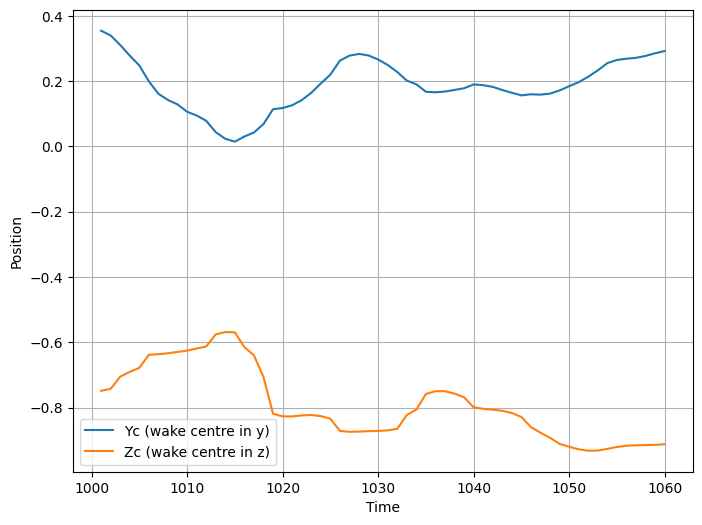

$Y_C/R$: mu = 0.188, sigma = 0.079
$Z_C/R$: mu = -0.791, sigma = 0.110


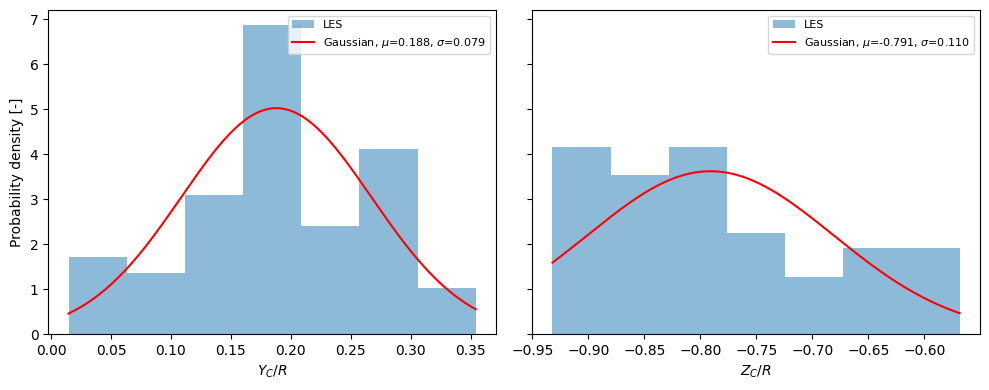

In [38]:
# Plot the wake centres
plt.figure(figsize=(8, 6))
plt.plot(U_anim.t.values, centres[:, 0], label='Yc (wake centre in y)')
plt.plot(U_anim.t.values, centres[:, 1], label='Zc (wake centre in z)')
plt.xlabel('Time')
plt.ylabel('Position')
plt.legend()
plt.grid()
plt.show()

mu, sigma = plot_histogram_with_gaussian_fit_from_wake_centres(yc_m / R, zc_m / R, "Wake Centres")